***
## **Temat projektu:** *Neural network-based trajectory prediction using Mean Squared Error (MSE). A Python simulation of predator-prey dynamics in a stochastic environment.*
***
### **Autorzy**
- ***Marta Marcinkowska***
- ***Jakub Wanat***

***
### Importy bibliotek oraz modułów

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src.actors import Rabbit, Wolf                       # Rabbit and Wolf Class
from src.model import create_online_model                 # Implementation of neural network
from src.utils import run_simulation, generate_report     # Simulation and plots generetion

d:\Projects\mse-trajectory-prediction\src\utils.py:9: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  if method is 'pos':


***

### **1 .Create Rabbit, Wolf class objects and implement MLPRegressor model**
#### *Uses fixed seed to guarantee research reproductibility*

In [3]:
rabbit = Rabbit(random_state=80)
wolf = Wolf()
nn_model = create_online_model()

***
### **2. Run simulation: Method 'pos' (Absolute coordinates)**
#### *The neural network learns by mapping historical absolute positions to the next absolute position (x, y).*

In [4]:
path_x, path_y, preds_x, preds_y, mse_history = run_simulation(rabbit, wolf, nn_model, n_steps=200, method='pos')

print("Simulation complete! Proceed to visualize results of neural network predictions")

Simulation complete! Proceed to visualize results of neural network predictions


***
### **3. Generated predicition report**

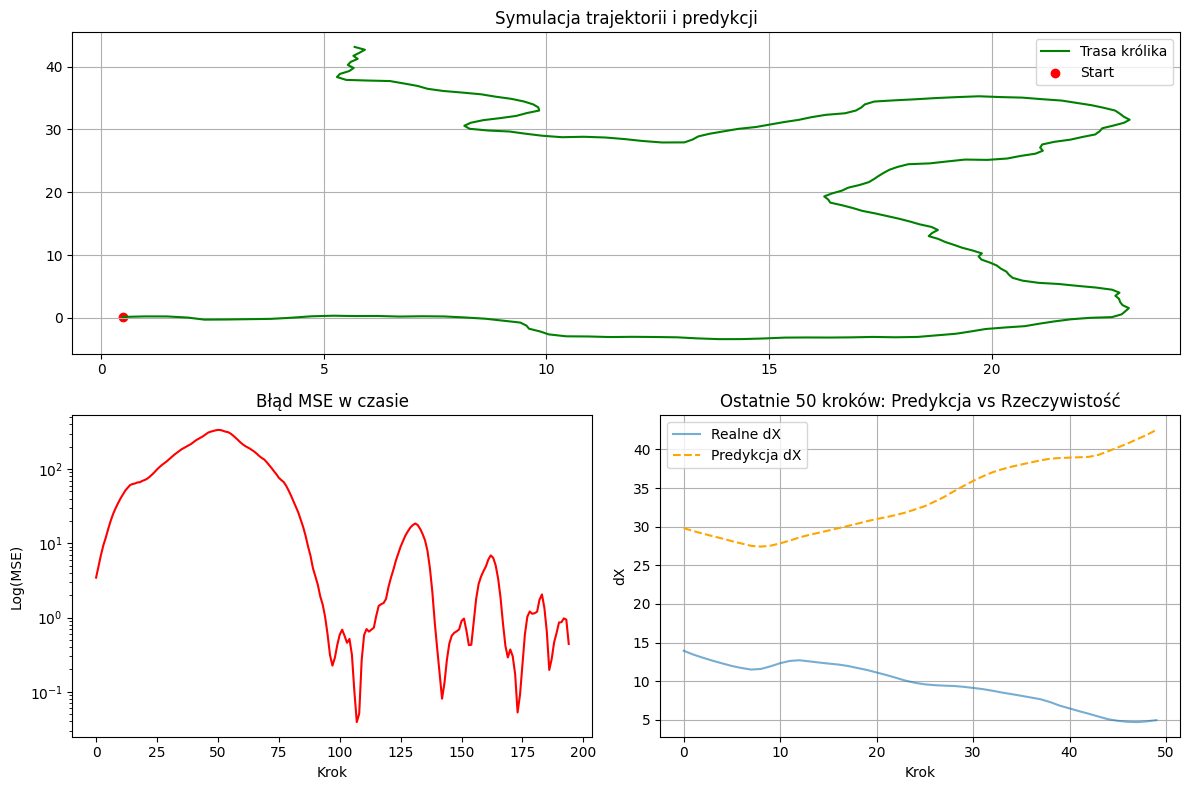

In [5]:
generate_report(path_x, path_y, preds_x, preds_y, mse_history)

***
### **4. Run simulation: Method 'delta' (Positional increments)**
#### *The neural network learns on movement vectors (deltas), making the model independent of the global coordinate system origin.*

In [6]:
delta_x, delta_y, preds_dx, preds_dy, dmse_history = run_simulation(rabbit, wolf, nn_model, n_steps=200, method='delta')

print("Simulation complete! Proceed to visualize results of neural network predictions")

Simulation complete! Proceed to visualize results of neural network predictions


***
### **5. Generated predicition report**

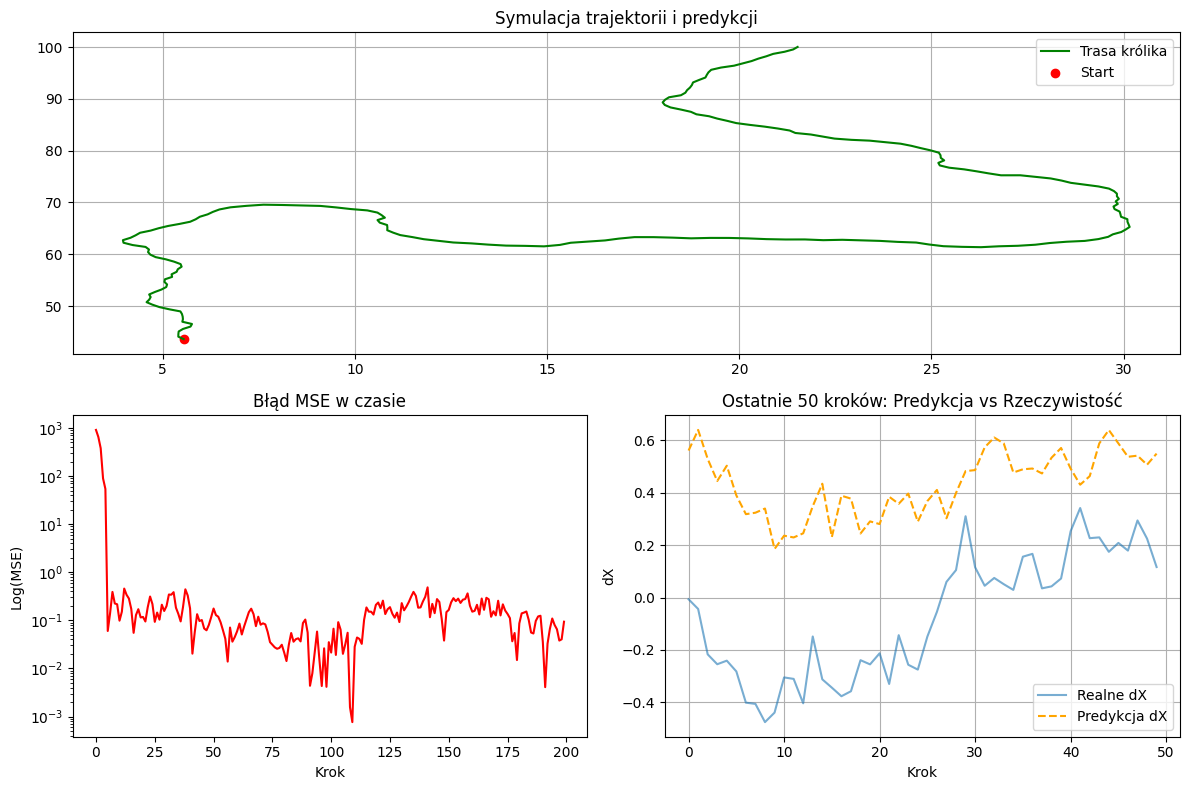

In [7]:
generate_report(delta_x, delta_y, preds_dx, preds_dy, dmse_history)

* **6. Summary of Differences (`pos` vs. `delta`)**:
  * **`pos` (Absolute Coordinates)**: The model predicts the exact spatial coordinates ($x, y$) of the target on the map. This approach relies on absolute positions tied to the global coordinate system, which can make it harder for the neural network to generalize and achieve fast convergence.
  * **`delta` (Positional Increments)**: The model predicts the movement vectors/changes ($\Delta x, \Delta y$) between consecutive steps rather than fixed locations. This approach is independent of the global map origin, ensuring faster convergence, higher stability, and a more natural emulation of a predator tracking dynamic, stochastic movement patterns.